# Introduction to using stdpopsim

## Workshop Outline
1. Basics of using Jupyter Notebooks
2. Overview of stdpopsim
3. How to use the Python API
4. How to use the command line interface
5. Example analyses
6. How to ask for help
7. Some examples of what stdpopsim cannot currently do
8. Teaser of how to contribute
9. Using stdpopsim after the workshop  
10. How to Navigate the stdpopsim library catalog

----------
## 1. Basics of using Jupyter Notebooks

Jupyter Notebooks have cells where you can write in Markdown and run code.  
To execute a cell, click the run button or press shift enter.

In [3]:
print('Try writing some Python here')

Try writing some Python here


In [4]:
%%bash
echo 'We can also use Bash magic. Try writing some Bash here'

We can also use Bash magic. Try writing some Bash here


---------
## 2. Overview of stdpopsim

### What is stdpopsim?
- Library of previously published population genetic models that can be used to simulate data
- Includes simple & complex demographic models, species specific recombination maps, and our newest feature-- selection
- Models have undergone rigorous quality control to ensure what we implement matches the original publication

### Why is stdpopsim useful?
- Increase reproducibility in population genetics modeling
- Less work for simulating data to test new inference methods
- Facilitate comparisons among inference methods

### Phase 1
Adrion et al. (2020). _A community-maintained standard library of population genetic models_. eLife. https://doi.org/10.7554/eLife.54967

- Focused just on demographic modeling
- Used msprime as simulation engine
- Realistic genetic maps for each species

### Phase 2
Lauterbur et al. (2023) _Expanding the stdpopsim species catalog, and lessons learned for realistic genome simulations_ eLife. https://doi.org/10.7554/eLife.84874.1

- Expanded the catalog to 21 species!
- SLiM now fully functional as backend simulation engine
- Functions for modeling selection introduced

### Phase 3
Gower et al (2025) _Accessible, Realistic Genome Simulation with Selection Using stdpopsim_ MBE.

- Implemented models of selection in numerous genomes
- Published DFEs included
- Species-specific annotations (CDS, exons) included

### Phase 4
Selection on quantitative traits!

- Leverages updates to SLiM 
- Distribution of mutation effects -> traits -> fitness
- Will preview beta version if there's time! 

### How to use stdpopsim
- Python API
  - more flexible
  - access to tskit functionality
  - faster for more replicates
- command line interface
  - one-liner
  - nice for people familiar with command line
  - easy to put into a bigger workflow

---------------
## 3. How to use the Python API

### Import the stdpopsim package

In [5]:
import stdpopsim

### Open the catalog page

Resources:
- [Catalog](https://stdpopsim.readthedocs.io/en/stable/catalog.html#)
- [Documentation](https://stdpopsim.readthedocs.io/en/stable/api.html)
- [Tutorials](https://stdpopsim.readthedocs.io/en/stable/tutorial.html#running-stdpopsim-with-the-python-interface-api)

### Which species?

Let's simulate humans.

_Use the [catalog](https://stdpopsim.readthedocs.io/en/stable/catalog.html#) to find available species_

https://stdpopsim.readthedocs.io/en/stable/api.html#stdpopsim.get_species

In [6]:
species = stdpopsim.get_species("HomSap")

### Which chromosome?

We'll simulate a region that is 10% of the length of chromosome 22.

Find what chromosomes are available in the [catalog](https://stdpopsim.readthedocs.io/en/stable/catalog.html#)

https://stdpopsim.readthedocs.io/en/stable/api.html#stdpopsim.Species.get_contig

In [36]:
contig = species.get_contig("chr22", left=0, right = 1e6)

Using a *real* genetic map

In [8]:
# contig = species.get_contig("chr22", genetic_map="HapMapII_GRCh38")

Using an alternative mutation rate:

In [9]:
# other_contig = stdpopsim.Contig(
#     mutation_rate=contig.mutation_rate*0.5,
#     recombination_map=contig.recombination_map
#     ) 



### Which demographic model?
https://stdpopsim.readthedocs.io/en/stable/api.html#stdpopsim.DemographicModel

Use the [catalog](https://stdpopsim.readthedocs.io/en/stable/catalog.html#) to find available demographic models.
You can also see them in the `species` object you just created:

In [10]:
for model in species.demographic_models:
    print(model.id)

OutOfAfricaExtendedNeandertalAdmixturePulse_3I21
OutOfAfrica_3G09
OutOfAfrica_2T12
Africa_1T12
AmericanAdmixture_4B18
OutOfAfricaArchaicAdmixture_5R19
Zigzag_1S14
AncientEurasia_9K19
PapuansOutOfAfrica_10J19
AshkSub_7G19
OutOfAfrica_4J17
Africa_1B08
AncientEurope_4A21


Then set your demographic model.
https://stdpopsim.readthedocs.io/en/stable/api.html#stdpopsim.Species.get_demographic_model

In [11]:
model = species.get_demographic_model('OutOfAfrica_3G09')

You may want to verify that the simulated populations are correct.

In [12]:
print([pop.name for pop in model.populations])

['YRI', 'CEU', 'CHB']


### How many samples?

In [13]:
samples = {"YRI": 5, "CHB": 5, "CEU": 0}

### Which simulator?
https://stdpopsim.readthedocs.io/en/stable/api.html#simulation-engines

In [14]:
engine = stdpopsim.get_engine('slim')

We're now ready to simulate:
https://stdpopsim.readthedocs.io/en/stable/api.html#stdpopsim.Engine.simulate

In [15]:
%%time
ts = engine.simulate(model, contig, samples, slim_scaling_factor=100, seed=1)

/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1660: SLiMScalingFactorWarning: You're using a scaling factor (100). This should give similar results for many situations, but is not equivalent, especially in the presence of selection. When using rescaling, you should be careful---do checks and compare results across different values of the scaling factor.
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1819: UnspecifiedSLiMWarni

CPU times: user 579 ms, sys: 81.2 ms, total: 660 ms
Wall time: 1.73 s


We're getting a lot of warnings. Don't ignore these!
At least, don't ignore them until you figure out why they are happening.
Some of these are because we're using approximations to make the simulations go extra fast;
the warnings are telling us that the approximations are approximate - so: beware!
If you're just using these for development (like us) then no worries.
But, if you use them for production, make sure to evaluate whether the approximations
are affecting your results!

This will turn off these warnings below:

In [16]:
import warnings
warnings.simplefilter("ignore", category=stdpopsim.SLiMScalingFactorWarning)
warnings.simplefilter("ignore", category=stdpopsim.UnspecifiedSLiMWarning)

## Output
### to a tree sequence file

In [17]:
display(ts)
ts.dump("OutOfAfrica_3G09_API.ts")

### to a vcf file

In [18]:
with open("OutOfAfrica_3G09_API.vcf", "w") as vcf_file:
    ts.write_vcf(vcf_file, contig_id='22')

Let's take a look at our vcf:

In [19]:
%%bash
ls

Intro_stdpopsim.ipynb
OutOfAfrica_3G09_API.trees
OutOfAfrica_3G09_API.ts
OutOfAfrica_3G09_API.vcf
README.md
sweeplog.txt


In [20]:
%%bash
head OutOfAfrica_3G09_API.vcf

##fileformat=VCFv4.2
##source=tskit 1.0.3
##FILTER=<ID=PASS,Description="All filters passed">
##contig=<ID=22,length=5081847>
##FORMAT=<ID=GT,Number=1,Type=String,Description="Genotype">
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	tsk_0	tsk_1	tsk_2	tsk_3	tsk_4	tsk_5	tsk_6	tsk_7	tsk_8	tsk_9
22	1147	0	T	G	.	PASS	.	GT	0|1	0|0	0|0	0|0	0|1	1|1	1|1	0|1	0|0	1|1
22	2272	1	T	G	.	PASS	.	GT	0|1	0|0	0|0	0|0	0|0	1|1	1|1	0|1	0|0	1|1
22	3666	2	T	C	.	PASS	.	GT	0|1	0|0	0|0	0|0	0|0	1|1	1|1	0|1	0|0	1|1
22	4045	3	C	T	.	PASS	.	GT	0|0	0|1	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0


### All together now!

In [37]:
import stdpopsim
species = stdpopsim.get_species("HomSap")
model = species.get_demographic_model('OutOfAfrica_3G09')
samples = {"YRI": 5, "CHB": 5, "CEU": 0}
engine = stdpopsim.get_engine('msprime') #note change of engine
contig = species.get_contig("chr22", left=0, right = 1e6)
ts = engine.simulate(model, contig, samples)
ts.dump("OutOfAfrica_3G09_API.trees")
with open("OutOfAfrica_3G09_API.vcf", "w") as vcf_file:
    ts.write_vcf(vcf_file, contig_id='22')

/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(


### Exercise: _Try to simulate the Arabidopsis South Middle Atlas piecewise constant size model!_

In [ ]:
species = stdpopsim.get_species("AraTha") #fill me!
model = species.get_demographic_model('SouthMiddleAtlas') #fill me!
samples =  #fill me!
engine = stdpopsim.get_engine('msprime')
contig = species.get_contig("", left=0, right = 1e5) #fill me!
ts = engine.simulate(model, contig, samples)

SyntaxError: invalid syntax (387162036.py, line 3)

## Questions?
--------------------

## Adding selection
To add selection into our simulations we need to add two components
1. the regions of the simulated chromosome that we wish to be under selection
2. the distribution of fitness effects (DFE) for new mutations in those regions

### Choose a DFE
DFEs appear in the catalog under each species. Here is the [human list](https://popsim-consortium.github.io/stdpopsim-docs/stable/catalog.html#sec_catalog_HomSap_dfe) 

a DFE is itself a python class that we can work with and compose onto chromosomes,
we have chosen to implement published ones in the catalog (e.g. the following example from Kim et al. 2017)


In [2]:
species = stdpopsim.get_species("HomSap")
dfe = species.get_dfe("Gamma_K17")
print(dfe)

DFE:
║  id               = Gamma_K17
║  description      = Deleterious Gamma DFE
║  long_description = Deleterious, gamma-distributed DFE estimated using 'Fit∂a∂i' from the
║                     nonsynonymous SFS in exons from a dataset of European humans by Kim et
║                     al. (2017).
║  citations        = ['https://doi.org/10.1534/genetics.116.197145']



We will set up a Contig, specifying the set of `intervals` that the chosen DFE will apply to:



In [16]:
import numpy as np
contig = species.get_contig("chr6", left=0, right=10000)
# make the DFE apply to the entire contig 
contig.add_dfe(intervals=np.array([[0, int(contig.length)]]), DFE=dfe)
# choose a demographic model if desired
model = species.get_demographic_model("OutOfAfrica_3G09")
samples = {"YRI": 20, "CEU": 20, "CHB": 20}

And now we will simulate. Simulations with selection are done forward in time using the SLiM simulation engine as a backend, so there are additional options we can specify about how to run our simulation 

In [17]:
%%time
engine = stdpopsim.get_engine("slim")
ts = engine.simulate(
    model,
    contig,
    samples,
    seed=123,
    slim_scaling_factor=20,#beware of scaling! 
    slim_burn_in=1, 

)

/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1660: SLiMScalingFactorWarning: You're using a scaling factor (20). This should give similar results for many situations, but is not equivalent, especially in the presence of selection. When using rescaling, you should be careful---do checks and compare results across different values of the scaling factor.
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1819: UnspecifiedSLiMWarnin

CPU times: user 695 ms, sys: 467 ms, total: 1.16 s
Wall time: 1.51 s


### Adding selection to exons
The catalog also has a certain number of annotations available, obtained from Ensembl. For instance, for humans we have:

In [18]:
for a in species.annotations:
    print(f"{a.id}: {a.description}")

# ensembl_havana_104_exons: Ensembl Havana exon annotations on GRCh38
# ensembl_havana_104_CDS: Ensembl Havana CDS annotations on GRCh38

ensembl_havana_104_exons: Ensembl Havana exon annotations on GRCh38
ensembl_havana_104_CDS: Ensembl Havana CDS annotations on GRCh38


We’ll simulate with the `HomSap/Gamma_K17` DFE, applied to all exons in the region of chromosome 6 that spans from 10 to 30 Mb. Parts of this chromosomal region that aren’t exons will have only neutral mutations. To do so, we extract the intervals from the Annotation object and use this in `Contig.add_dfe()`:

In [ ]:
%%time
species = stdpopsim.get_species("HomSap")
dfe = species.get_dfe("Gamma_K17")
contig = species.get_contig("chr6", left=10e6, right=30e6)
model = species.get_demographic_model("OutOfAfrica_3G09")
samples = {"YRI": 50, "CEU": 50, "CHB": 50}

exons = species.get_annotations("ensembl_havana_104_exons")
exon_intervals = exons.get_chromosome_annotations("chr6")
contig.add_dfe(intervals=exon_intervals, DFE=dfe)

engine = stdpopsim.get_engine("slim")
ts = engine.simulate(
    model,
    contig,
    samples,
    seed=236,
    slim_scaling_factor=20,
    slim_burn_in=10,
)

/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1660: SLiMScalingFactorWarning: You're using a scaling factor (20). This should give similar results for many situations, but is not equivalent, especially in the presence of selection. When using rescaling, you should be careful---do checks and compare results across different values of the scaling factor.
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1819: UnspecifiedSLiMWarnin

CPU times: user 5.28 s, sys: 507 ms, total: 5.78 s
Wall time: 11 s


This is a quick example because of the heavy scaling $Q=20$ that we are using but nonetheless there is lower diversity in exons than outside of them:


In [20]:
breaks, labels = contig.dfe_breakpoints()

diffs = ts.diversity(windows=breaks, span_normalise=False)
pi = (
    np.sum(diffs[labels == 1]) / np.sum(np.diff(breaks)[labels == 1]),
    np.sum(diffs[labels == 0]) / np.sum(np.diff(breaks)[labels == 0]),
)

print(
    f"Mean sequence diversity in exons is {1000 * pi[0]:.3f} differences per Kb,\n"
    f"and outside of exons it is {1000 * pi[1]:.3f} differences per Kb."
)


Mean sequence diversity in exons is 0.208 differences per Kb,
and outside of exons it is 0.383 differences per Kb.


### Exercise: _Try to simulate the Arabidopsis South Middle Atlas piecewise constant size model with selection on exons and a Gamma DFE!_

In [ ]:
species = stdpopsim.get_species("") #fill me!
model = species.get_demographic_model('') #fill me!
samples =  #fill me!


contig = species.get_contig("", left=0, right = 1e4) #fill me!
dfe = species.get_dfe("") #fill me!
exons = species.get_annotations("") #fill me!
exon_intervals = exons.get_chromosome_annotations("") #fill me!
contig.add_dfe(intervals=exon_intervals, DFE=dfe)

engine = stdpopsim.get_engine('') #fill me!
ts = engine.simulate(
    model,
    contig,
    samples,
    seed=236,
    slim_scaling_factor=20,
    slim_burn_in=10,
)

### Questions?

---------------
## 4. How to use the command line interface
Resources:
- [Documentation](https://stdpopsim.readthedocs.io/en/stable/cli_arguments.html)
- [Tutorials](https://stdpopsim.readthedocs.io/en/stable/tutorial.html#running-stdpopsim-with-the-command-line-interface-cli)

### Run stdpopsim with the help option

In [21]:
%%bash
stdpopsim --help

usage: stdpopsim [-h] [-V] [-v | -q] [-c CACHE_DIR] [-e {msprime,slim}]
                 [--msprime-model {hudson,dtwf,smc,smc_prime}]
                 [--msprime-change-model T MODEL] [--slim-path PATH]
                 [--slim-script] [--slim-scaling-factor Q] [--slim-burn-in X]
                 {AedAeg,AnaPla,AnoCar,AnoGam,ApiMel,AraTha,BosTau,CaeEle,CanFam,ChlRei,DroMel,DroSec,EscCol,GasAcu,GorGor,HelAnn,HelMel,HomSap,MusMus,OrySat,PanTro,PapAnu,PhoSin,PonAbe,RatNor,StrAga,SusScr,download-genetic-maps}
                 ...

Command line interface for stdpopsim.

positional arguments:
  {AedAeg,AnaPla,AnoCar,AnoGam,ApiMel,AraTha,BosTau,CaeEle,CanFam,ChlRei,DroMel,DroSec,EscCol,GasAcu,GorGor,HelAnn,HelMel,HomSap,MusMus,OrySat,PanTro,PapAnu,PhoSin,PonAbe,RatNor,StrAga,SusScr,download-genetic-maps}
    AedAeg              Run simulations for Aedes aegypti.
    AnaPla              Run simulations for Anas platyrhynchos.
    AnoCar              Run simulations for Anolis carolinensis.
  

`stdpopsim` uses a combination of [_positional arguments_](https://stdpopsim.readthedocs.io/en/stable/cli_arguments.html#Positional%20Arguments), which are required, and [_named arguments_](https://stdpopsim.readthedocs.io/en/stable/cli_arguments.html#Named%20Arguments), which are optional.

### Find your species and run stdpopsim with that species with the help option

In [22]:
%%bash
stdpopsim HomSap --help

usage: stdpopsim HomSap [-h] [--help-models [HELP_MODELS]] [-b BIBTEX_FILE]
                        [--help-genetic-maps [HELP_GENETIC_MAPS]] [-D] [-g]
                        [--help-dfes [HELP_DFES]] [-c] [-L LENGTH]
                        [-i INCLUSION_MASK] [-e EXCLUSION_MASK]
                        [-l LENGTH_MULTIPLIER] [--left LEFT] [--right RIGHT]
                        [-s SEED] [--keep-mutation-ids-as-alleles] [-d]
                        [--dfe] [--dfe-interval] [--dfe-bed-file]
                        [--help-annotations [HELP_ANNOTATIONS]]
                        [--dfe-annotation] [-o OUTPUT]
                        samples [samples ...]

Run simulations for Homo sapiens using up-to-date genome information,
genetic maps and simulation models from the literature. NOTE: By
default, the tskit '.trees' binary file is written to stdout,so you
should either redirect this to a file or use the '--output' option to
specify a filename.

Default population parameters for Homo sap

### Find your model and run stdpopsim with that model with the help option

In [23]:
%%bash
stdpopsim HomSap \
        --help-models


All simulation models for Homo sapiens

Africa_1B08: African-americans population
     African-American two-epoch instantaneous growth model from Boyko
    et al 2008, fit to the synonymous SFS for the 11 of 15 African
    Americans showing the least European ancestry, using coalescent
    simulations with recombination with the maximum likelihood method
    of Williamson et al 2005; times were calibrated assuming 3e5
    generations since human-chimp divergence and fitting the number of
    synonymous human-chimp differences. Mutation and recombination
    rates were assumed to be the same (1.8e-8).

    Populations:
        African_Americans: African-Americans from Boyko et al 2008

Africa_1T12: African population
     The model is a simplification of the two population Tennesen et
    al. model with the European-American population removed so that we
    are modeling the African population in isolation.

    Populations:
        AFR: African

AmericanAdmixture_4B18: American admixt

## Run a simulation
- pick the number of samples for each population
- pick a chromosome
- do you want a fraction of the chromosome?
- decide on an output file

Let's do a dry run first by using `-D`.

In [38]:
%%bash
stdpopsim HomSap YRI:10 CEU:10 CHB:10\
    --demographic-model OutOfAfrica_3G09 \
    --chromosome chr22 \
    --left 0 \
    --right 1e5 \
    --output OutOfAfrica_3G09_CLI.ts \
    -D

Simulation information:
    Engine: msprime (1.4.4)
    Model id: OutOfAfrica_3G09
    Model description: Three population out-of-Africa
    Population: number_samples (sampling_time_generations):
        YRI: 10 (0)
        CEU: 10 (0)
        CHB: 10 (0)
Contig Description:
    Contig origin: chr22:0-100000
    Contig length: 50818468.0
    Contig ploidy: 2
    Mutation rate: 2.35e-08
    Recombination rate: 2.1057233894035443e-08
    Genetic map: None

If you use this simulation in published work, please cite:
[stdpopsim]
Adrion et al., 2020: https://doi.org/10.7554/eLife.54967
[stdpopsim]
Lauterbur et al., 2023: https://doi.org/10.7554/eLife.84874
[simulation engine]
Kelleher et al., 2016: https://doi.org/10.1371/journal.pcbi.1004842
[generation time]
Tremblay and Vézina, 2000: https://doi.org/10.1086/302770
[population size]
Takahata, 1993: https://doi.org/10.1093/oxfordjournals.molbev.a039995
[genome assembly]
International Human Genome Sequencing Consortium, 2001: http://dx.doi.

Does that look right? If so, let's do the simulation!

In [40]:
%%bash
stdpopsim HomSap YRI:10 CEU:10 CHB:10\
         --demographic-model OutOfAfrica_3G09 \
         --chromosome chr22 \
         --left 0 \
         --right 1e5 \
         --output OutOfAfrica_3G09_CLI.ts

Simulation information:
    Engine: msprime (1.4.4)
    Model id: OutOfAfrica_3G09
    Model description: Three population out-of-Africa
    Population: number_samples (sampling_time_generations):
        YRI: 10 (0)
        CEU: 10 (0)
        CHB: 10 (0)
Contig Description:
    Contig origin: chr22:0-100000
    Contig length: 50818468.0
    Contig ploidy: 2
    Mutation rate: 2.35e-08
    Recombination rate: 2.1057233894035443e-08
    Genetic map: None

If you use this simulation in published work, please cite:
[stdpopsim]
Adrion et al., 2020: https://doi.org/10.7554/eLife.54967
[stdpopsim]
Lauterbur et al., 2023: https://doi.org/10.7554/eLife.84874
[simulation engine]
Kelleher et al., 2016: https://doi.org/10.1371/journal.pcbi.1004842
[generation time]
Tremblay and Vézina, 2000: https://doi.org/10.1086/302770
[population size]
Takahata, 1993: https://doi.org/10.1093/oxfordjournals.molbev.a039995
[genome assembly]
International Human Genome Sequencing Consortium, 2001: http://dx.doi.

In [41]:
%%bash
tskit vcf OutOfAfrica_3G09_CLI.ts > OutOfAfrica_3G09_CLI.vcf

Let's take a look at our vcf.

In [42]:
%%bash
ls

Intro_stdpopsim.ipynb
OutOfAfrica_3G09_API.trees
OutOfAfrica_3G09_API.ts
OutOfAfrica_3G09_API.vcf
OutOfAfrica_3G09_CLI.ts
OutOfAfrica_3G09_CLI.vcf
README.md
sweeplog.txt


In [28]:
%%bash
head OutOfAfrica_3G09_CLI.vcf

##fileformat=VCFv4.2
##source=tskit 1.0.3
##FILTER=<ID=PASS,Description="All filters passed">
##contig=<ID=1,length=5081847>
##FORMAT=<ID=GT,Number=1,Type=String,Description="Genotype">
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	tsk_0	tsk_1	tsk_2	tsk_3	tsk_4	tsk_5	tsk_6	tsk_7	tsk_8	tsk_9	tsk_10	tsk_11	tsk_12	tsk_13	tsk_14	tsk_15	tsk_16	tsk_17	tsk_18	tsk_19	tsk_20	tsk_21	tsk_22	tsk_23	tsk_24	tsk_25	tsk_26	tsk_27	tsk_28	tsk_29
1	282	0	G	T	.	PASS	.	GT	0|0	0|1	0|0	1|1	0|1	0|1	0|1	0|0	1|0	1|0	0|0	1|0	0|1	1|1	1|1	1|0	1|1	0|1	1|1	1|0	0|1	0|1	1|0	1|0	1|1	0|0	1|0	1|1	0|1	1|1
1	354	1	A	C	.	PASS	.	GT	1|1	1|0	1|1	0|0	1|0	1|0	1|0	1|1	0|1	0|1	1|1	0|1	1|0	0|0	0|0	0|1	0|0	1|0	0|0	0|1	1|0	1|0	0|1	0|1	0|0	1|1	0|1	0|0	1|0	0|0
1	389	2	A	C	.	PASS	.	GT	0|0	0|0	0|0	0|0	1|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0
1	460	3	G	A	.	PASS	.	GT	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|1	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	

### _Try to simulate the Arabidopsis South Middle Atlas piecewise constant size model!_

Bonus: from the `--help` output, can you see how you might use one of the published genetic maps in this simulation? (perhaps the *SalomeAveraged_TAIR7* map?)

In [ ]:
%%bash
stdpopsim #fill me!

### Questions?

## 5.Example analyses

### using scikit-allel to visualize population structure
Quick look at using stdpopsim together with scikit-allel to examine PCA of genetic variation from simulations.

First we set the model:

In [44]:
import allel
import stdpopsim
from matplotlib import pyplot as plt
import seaborn as sns

species = stdpopsim.get_species("HomSap")
model = species.get_demographic_model('OutOfAfrica_3G09')
samples = {"YRI": 50, "CHB": 50, "CEU": 50}
engine = stdpopsim.get_engine('msprime')
contig = species.get_contig("chr22", left = 0, right = 1e5)

next we will simulate and use tools from scikit-allel to go from tree sequences to genotypes. we'll output the first few rows of the genotype array produced by allel

In [45]:
ts = engine.simulate(model, contig, samples)
haps = allel.HaplotypeArray(ts.genotype_matrix())
gns = haps.to_genotypes(ploidy=2)
gns

/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(


<GenotypeArray shape=(446, 150, 2) dtype=int32>
0/0 0/0 0/0 0/0 0/0 ... 0/0 0/0 0/0 0/0 0/0
0/0 0/0 0/0 0/0 0/0 ... 0/0 0/0 0/0 0/0 0/0
0/0 0/0 0/1 0/0 0/0 ... 0/0 0/0 0/0 0/0 0/0
...
0/0 0/0 0/0 0/0 0/0 ... 0/0 0/0 0/0 0/0 0/0
1/0 1/0 0/1 0/1 0/1 ... 1/0 0/1 0/1 1/1 0/0
0/0 0/0 0/0 0/1 0/0 ... 0/0 0/0 0/0 0/0 0/0

now we're ready to do PCA. we'll do the decomposition and then plot, note that allel requires a flattened version of the genotype array above that codes individual genotypes as 0/1/2 according to the number of reference alleles

note: if you get an error here, you may need to re-run the simulation and try again

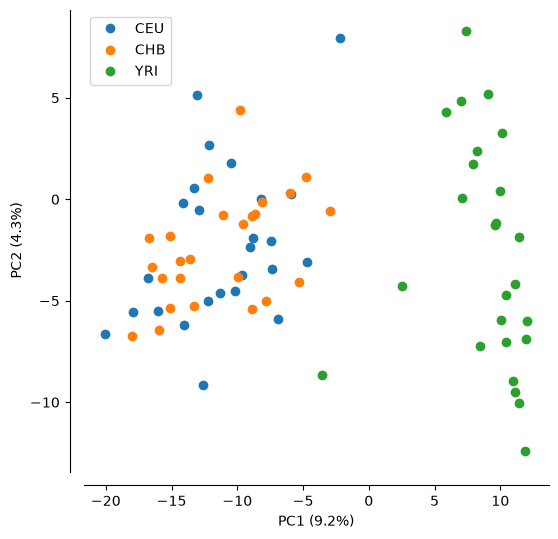

In [46]:

def plot_pca_coords(coords, fitted, pc1, pc2, ax):
    x = coords[:, pc1]
    y = coords[:, pc2]
    ax.plot(x[0:25], y[0:25], marker='o', linestyle=' ', label='CEU', markersize=6)
    ax.plot(x[25:50], y[25:50], marker='o', linestyle=' ', label='CHB', markersize=6)
    ax.plot(x[50:75], y[50:75], marker='o', linestyle=' ', label='YRI', markersize=6)

    ax.set_xlabel('PC%s (%.1f%%)' % (pc1+1, fitted.explained_variance_ratio_[pc1]*100))
    ax.set_ylabel('PC%s (%.1f%%)' % (pc2+1, fitted.explained_variance_ratio_[pc2]*100))


fig, ax = plt.subplots(figsize=(6, 6))
sns.despine(ax=ax, offset=10)

coords, fitted = allel.pca(gns.to_n_ref())
plot_pca_coords(coords, fitted, 0, 1, ax)
ax.legend()



## Reduction in polymorphism due to selection
Let's simulate the same out-of-Africa model as above, add selection at exons, and compare polymorphism


In [ ]:
import stdpopsim
import tskit
from progressbar import ProgressBar #This is just to get a progress bar
import warnings

#helper function for next step
def make_sample_list(ts):
    sample_list = []
    for pop in range(0, ts.num_populations):
        sample_list.append(ts.samples(pop).tolist())
    return sample_list

species = stdpopsim.get_species("HomSap")
model = species.get_demographic_model('OutOfAfrica_3G09')
samples = {"YRI": 10, "CHB": 10, "CEU": 10}
engine = stdpopsim.get_engine('msprime')
contig = species.get_contig("chr8", left=1e6, right=2e6)
contig_neutral = species.get_contig("chr8", left=1e6, right=2e6)

exons = species.get_annotations("ensembl_havana_104_exons")
exon_intervals = exons.get_chromosome_annotations("chr8")
dfe = species.get_dfe("Gamma_K17")
contig.add_dfe(intervals=exon_intervals, DFE=dfe)

engine = stdpopsim.get_engine("slim")

n = 50
pi_list = []
pi_neutral_list = []
pbar = ProgressBar() #This is just to get a progress bar
for i in pbar(range(n)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=stdpopsim.SLiMScalingFactorWarning)
        warnings.simplefilter("ignore", category=stdpopsim.UnspecifiedSLiMWarning)
        warnings.simplefilter("ignore", category=UserWarning)
        ts = engine.simulate(model, contig, samples, slim_scaling_factor=100, slim_burn_in=1)
        ts_neutral = engine.simulate(model, contig_neutral, samples, slim_scaling_factor=100, slim_burn_in=1)
    sample_list = make_sample_list(ts)
    pi_list.append(ts.diversity(sample_sets=sample_list))
    pi_neutral_list.append(ts_neutral.diversity(sample_sets=sample_list))
print('Done simulating {} replicates!'.format(n))


KeyboardInterrupt: 

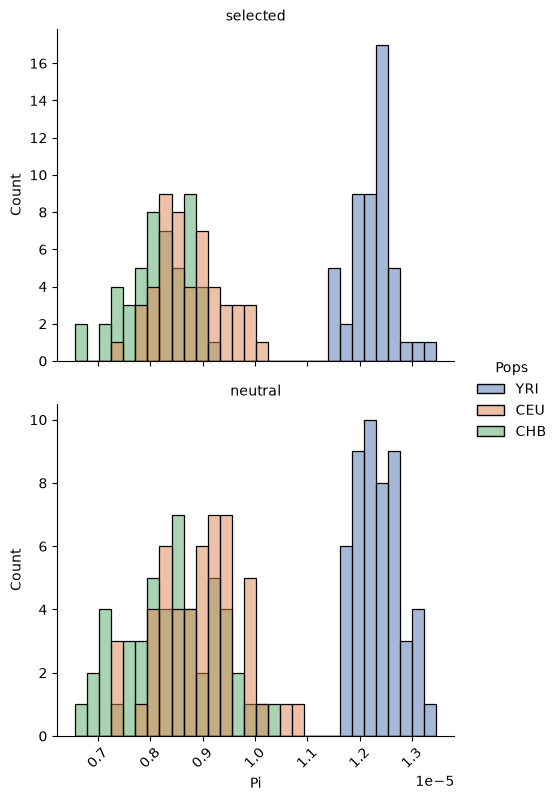

mean_pi     sd_pi
Pops type                        
CEU  neutral   0.891143  0.076579
     selected  0.873147  0.063421
CHB  neutral   0.844243  0.088806
     selected  0.816350  0.061236
YRI  neutral   1.236286  0.040512
     selected  1.225365  0.040125

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pi_df_sel = pd.DataFrame(
    data=pi_list, columns=[pop.name for pop in model.populations])
pi_df_sel_melted = pd.melt(pi_df_sel, var_name='Pops', value_name='Pi')
pi_df_sel_melted['type'] = "selected"

pi_df_neutral = pd.DataFrame(
    data=pi_neutral_list, columns=[pop.name for pop in model.populations])
pi_df_neu_melted = pd.melt(pi_df_neutral, var_name='Pops', value_name='Pi')
pi_df_neu_melted['type'] = "neutral"

pi_df = pd.concat([pi_df_sel_melted, pi_df_neu_melted])

pops = [pop.name for pop in model.populations]
colors = sns.color_palette("deep", n_colors=len(pops))
palette = dict(zip(pops, colors))

g = sns.displot(
    data=pi_df, x="Pi", hue="Pops", row="type",
    hue_order=pops, palette=palette, bins=30,
    height=4, aspect=1.2,
    facet_kws=dict(sharex=True, sharey=False),
)

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)

g.set_titles("{row_name}")
plt.show()

pi_df.groupby(["Pops", "type"]).agg(
    mean_pi=("Pi", lambda x: np.mean(x)*1e5),
    sd_pi=("Pi", lambda x: np.std(x)*1e5),
)


## Approximate the allele frequency trajectory during a selective sweeep

In [26]:
import stdpopsim
import numpy as np

species = stdpopsim.get_species("HomSap")
model = species.get_demographic_model('OutOfAfrica_3G09')
samples = {"YRI": 10, "CHB": 10, "CEU": 10}
engine = stdpopsim.get_engine('msprime')
contig = species.get_contig("chr8", left=1e6, right=5e6)

dfe = species.get_dfe("Gamma_K17")
exons = species.get_annotations("ensembl_havana_104_exons")
exon_intervals = exons.get_chromosome_annotations("chr8")
contig.add_dfe(intervals=exon_intervals, DFE=dfe)

engine = stdpopsim.get_engine("slim")

locus = f"sweep1"
selpop = model.populations[0].name
coordinate = int(3e6)
contig.add_single_site(id=locus, coordinate=coordinate)

selcoef = 0.04
mutgen = 10*(2*np.log(4*1e4)/selcoef)

sweep_events = stdpopsim.selective_sweep(
    single_site_id=locus,
    population=selpop,
    selection_coeff=selcoef,
    mutation_generation_ago=mutgen,
    globally_adaptive=True,
)

# simulate and write out trees / vcf
ts = engine.simulate(
    contig=contig,
    demographic_model=model,
    samples=samples,
    slim_burn_in=1.0,
    extended_events=sweep_events,
    seed=42,
    slim_scaling_factor=10,
    logfile="sweeplog.txt",
    logfile_interval=10,
)


/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/slim_engine.py:1660: SLiMScalingFactorWarning: You're using a scaling factor (10). This should give similar results for many situations, but is not equivalent, especially in the presence of selection. When using rescaling, you should be careful---do checks and compare results across different values of the scaling factor.
  warnings.warn(
/Users/silastittes/miniforge3/envs/stdpopsim-environment/lib/python3.11/site-packages/stdpopsim/engines.py:113: UserWarning: The demographic model has mutation rate 2.35e-08, but this simulation used the contig's mutation rate 1.29e-08. Diversity levels may be different than expected for this species. For details see documentation at https://popsim-consortium.github.io/stdpopsim-docs/stable/tutorial.html
  warnings.warn(


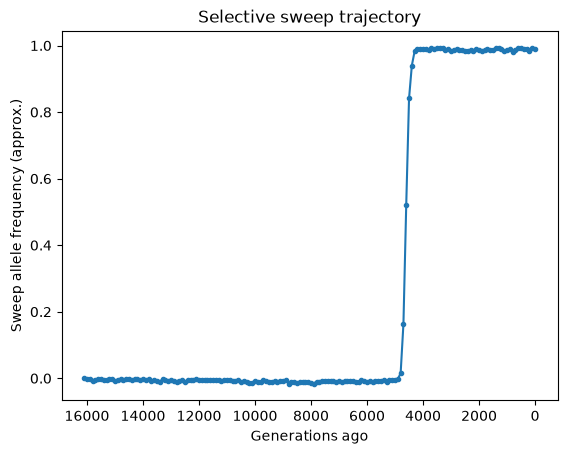

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

Q = 10                    # slim_scaling_factor
s_slim = selcoef * Q      # rescaled selection coefficient

fitness_df = pd.read_csv("sweeplog.txt")

# with h = 0.5, mean fitness w(p) = 1 + 2pq·hs + p²·s => = 1 + s·p
# p = (w(p) - 1) / s
fitness_df["p"] = (fitness_df["fitness_p0_mean"] - 1) / s_slim

# convert SLiM ticks to generations before present
fitness_df["gens_ago"] = (fitness_df["tick"].max() - fitness_df["tick"]) * Q

plt.plot(fitness_df["gens_ago"], fitness_df["p"], marker=".")
plt.gca().invert_xaxis()
plt.xlabel("Generations ago")
plt.ylabel("Sweep allele frequency (approx.)")
plt.title("Selective sweep trajectory")
plt.show()


### Questions?

### COMING SOON: TRAITS!

In [ ]:
# NOTE: INCOMPLETE CHUNK FOR SAKE OF PROMOTION
# USING TRAITS REQUIRES PRE-RELEASE OF SLIM AND STDPOPSIM TO BE INSTALLED LOCALLY BY USER

"""
species = stdpopsim.get_species("HomSap")
contig = species.get_contig("chr22", left=10_000_000, right=11_000_000)
contig.add_dme(intervals=np.array([[0, contig.length]]), DME=dme)
model = species.get_demographic_model("OutOfAfrica_3G09")

traits = [
    stdpopsim.Trait(id="height", type="additive"),
    stdpopsim.Trait(id="disease", type="additive", transform="liability",
                    transform_args=[0.0, 1.0]),  # (center, slope)
]

tm.add_environment(
    id="env_height",
    trait_ids=["height"],
    distribution_type="n",
    distribution_args=[0, 1.0],  # (mean, sd)
    # optional: time_intervals=[(0, float("inf"))], population_list=["YRI"]
)

tm = stdpopsim.TraitsModel(traits=traits)
 
engine = stdpopsim.get_engine("slim")
ts = engine.simulate(
    model, contig, samples={"YRI": 50, "CEU": 50},
    traits_model=tm,
    seed=1,
    slim_scaling_factor=10,  # speed; see the warning in the docs
)
"""

---------
## 6. How to ask for help
- Have you read the [documentation](https://stdpopsim.readthedocs.io/en/stable/index.html)?
- Search open and closed [GitHub issues](https://github.com/popsim-consortium/stdpopsim/issues?q=is%3Aissue)
- Write a new [GitHub issue](https://github.com/popsim-consortium/stdpopsim/issues/new/choose)
- Join the PopSim Slack workspace and post in the #newbie-help channel ([invite link here](https://join.slack.com/t/popsimgroup/shared_invite/zt-1ql1axuk6-ymqHmu9NQJ1PqfZKFC6SzQ))

---------
## 7. Some examples of what stdpopsim cannot currently do
- simulate species or demographic models that are not in the catalog 
    - if you want to do this, if it is a published model - submit it to stdpopsim, if it is not a published model, use a simulator (e.g. msprime, slim)
- simulate missing data and errors (on the horizon!)


----------
## 8. Teaser of [how to contribute](https://stdpopsim.readthedocs.io/en/stable/development.html#)

- Write [GitHub issues](https://github.com/popsim-consortium/stdpopsim/issues/new/choose)!
- [Add new species](https://stdpopsim.readthedocs.io/en/stable/development.html#adding-a-new-species)
- [Add new demographic models](https://stdpopsim.readthedocs.io/en/stable/development.html#adding-a-new-demographic-model)
- Help with Documentation and tutorials

-----------
## 9. Using stdpopsim on your own after the workshop
- Play in a Jupyter Notebook Binder
  - Using this one [![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/popsim-consortium/workshops.git/main?filepath=intro_stdpopsim%2FIntro_stdpopsim.ipynb)
  - In the Binder associated with the [stdpopsim GitHub repository](https://github.com/popsim-consortium/stdpopsim) [![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/popsim-consortium/stdpopsim/master?filepath=stdpopsim_example.ipynb)
- Install stdpopsim locally following the [instructions in the documentation](https://stdpopsim.readthedocs.io/en/stable/installation.html)
- Consult the [stdpopsim documentation](https://stdpopsim.readthedocs.io/en/stable/installation.html)

---------
## 10. How to Navigate the [stdpopsim library catalog](https://stdpopsim.readthedocs.io/en/stable/catalog.html)

### The Catalog is organized first by species.

_How many species are there?_

![](images/catalog.png)


### Each species has a set of defining attributes. 

_What are the attributes?_

![](images/species_attributes.png)

### Each species has defined genome parameters.

_What are the genome parameters?_

![](images/genome_params.png)

### Some species have a genetic map.

Genetic maps are stored on AWS and downloaded to cache when used.

![](images/genetic_maps.png)

### Some species have demographic models.

All models are from published models.

_What models are available? Are there any you recognize from the literature?_

![](images/models.png)

### Each model has a description and set of defining attributes. 

_What are the attributes?_

![](images/model_attr.png)

### Each model has a table of defined model parameters from the publication. 

_Can you find where in the original publication the model parameters are given?_

![](images/model_params.png)